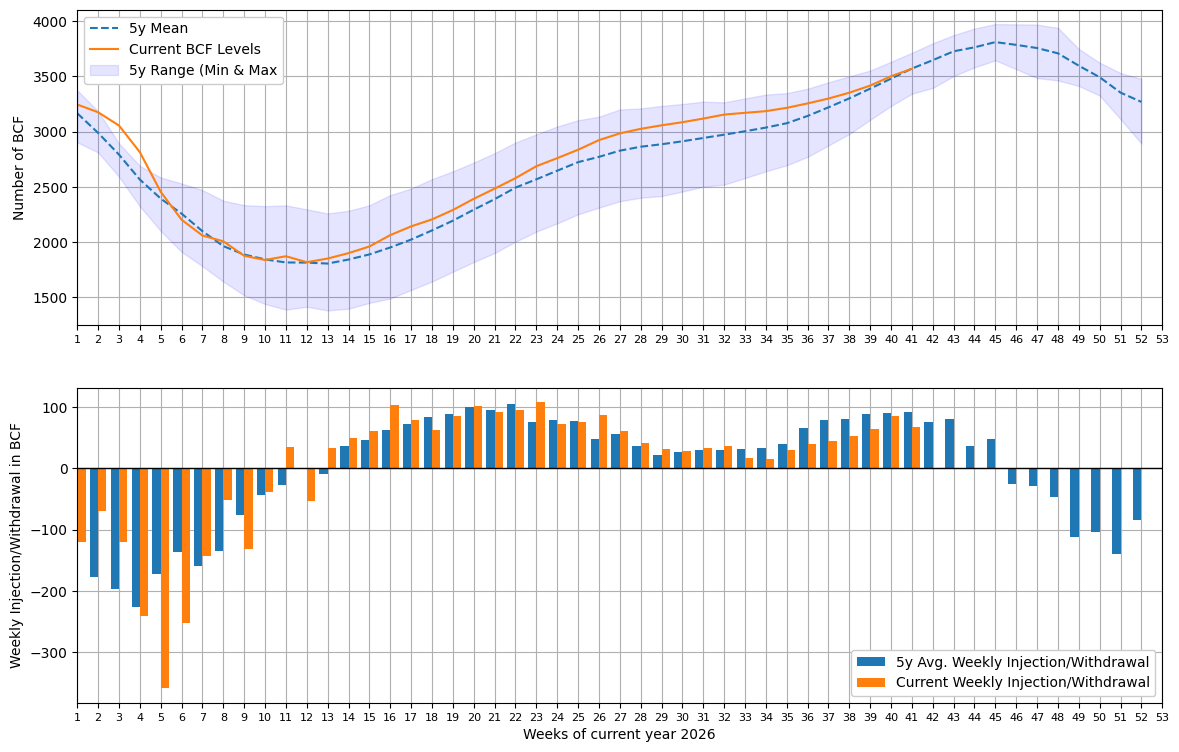

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from datetime import date 


API_KEY = "K1kHaYDyYlIRtPWWOTMA8JBkIUjX2Vsgx7yUDSUP"
url = "https://api.eia.gov/v2/natural-gas/stor/wkly/data/?"


#get it to where its last 5 years no matter current
#make it to where we can make sure its only current year
current_year = date.today().year
past_five = list(range(current_year - 5, current_year))

#get data from api key
parameters = {"api_key" : API_KEY,
              "frequency" : "weekly",
              "data[0]" : "value",
              "facets[series][]" : "NW2_EPG0_SWO_R48_BCF",
              "start" : f"{current_year - 6}-01-01"
             }


#-----------------Preparing our data
#sends an http GET request to the API to retrieve data
response = requests.get(url, params=parameters)
#.json() converts the text response formatted in JSON to a python dictionary
data = response.json()["response"]["data"] 


df=pd.DataFrame(data)
df=df[["period", "value"]] #

df["period"] = pd.to_datetime(df["period"])
df["value"] = df["value"].astype(float)

#sometimes data is messy so this ensures our time series is in order
df = df.sort_values("period")

df["weekly change"] = df["value"].diff()

df["year"] = df["period"].dt.isocalendar().year
df["week"] = df["period"].dt.isocalendar().week

#Create a pivot table to make it easier to graph
BCF_levels = df.pivot_table(index= "week", columns = "year",values = "value")

change = df.pivot_table(index = "week", columns = "year", values = "weekly change")

#------------------ Getting Ready to Plot
#get 5 year mean and current levels ready to plot
fivey_mean = BCF_levels[past_five].mean(axis=1)
current_BCF_levels = BCF_levels[current_year]

#min and max for range on chart
fivey_min = BCF_levels[past_five].min(axis=1)
fivey_max = BCF_levels[past_five].max(axis=1)


#5 year injection avg and current weekly injections
weekly_inj_avg = change[past_five].mean(axis=1)
current_change = change[current_year]


#prepare charts 
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (14, 9), sharex=True)

#---------------------------- Plotting the Data
#ploting 5 year mean
ax1.plot(fivey_mean, linestyle = ("--"), label = "5y Mean")
#plotting current levels against 5 year mean
ax1.plot(current_BCF_levels, linestyle = ("-"), label = "Current BCF Levels")
#labeling ax1
ax1.tick_params(labelbottom = True)
#plotting 5 year range
ax1.fill_between(fivey_mean.index, fivey_min, fivey_max, 
                 color = "blue", alpha = 0.1, label = "5y Range (Min & Max") # This one
#ax1 legend and y label
ax1.legend(loc = "upper left", framealpha = 1)
ax1.set_ylabel("Number of BCF")

#plotting weekly injections against 5y avg
ax2.bar(change.index - 0.2, weekly_inj_avg, width = 0.4, label = "5y Avg. Weekly Injection/Withdrawal")
ax2.bar(change.index + 0.2, current_change, width = 0.4, label = "Current Weekly Injection/Withdrawal")
ax2.set_xlabel(f"Weeks of current year {current_year}")
ax2.set_ylabel("Weekly Injection/Withdrawal in BCF")

#legend for ax2
ax2.legend(loc = "lower right", framealpha = 1)

# y = 0 to better see injections
y = 0
ax2.axhline(y, color = "black", linewidth = 1)

#setting the x axis so it matches the start and end
for ax in (ax1, ax2):
    ax.set_xlim (1, 53)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.set_axisbelow(True)

#adjust
ax1.tick_params(axis = 'x', labelsize = 8)
ax2.tick_params(axis = 'x', labelsize = 8)

ax1.grid()
ax2.grid()
plt.show()

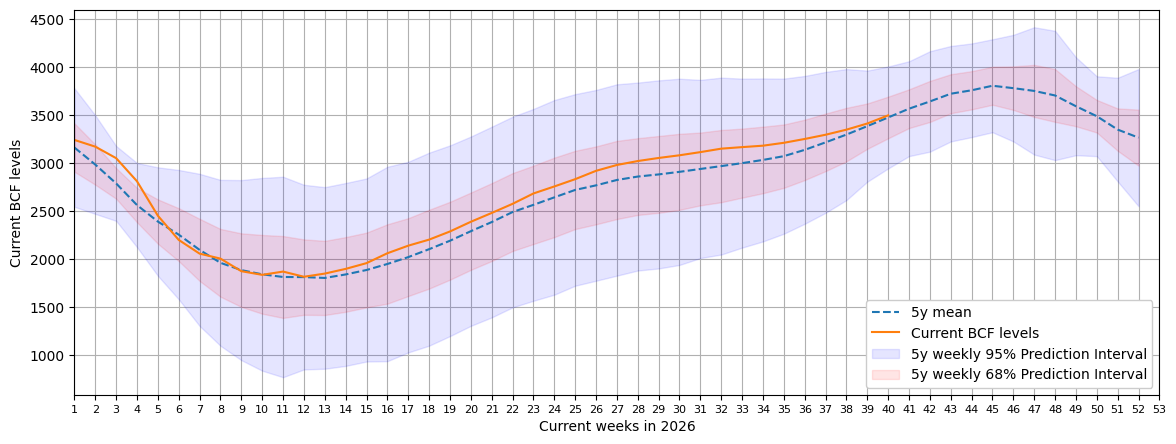

In [10]:
#parameters required for prediction interval
sample_avg = BCF_levels[past_five].mean(axis=1)
t_95 = 2.7765
t_68 = 1.134
n = 5 # n = 5 for 5 values for each week over 5 years
sd = BCF_levels[past_five].std(axis=1)

#BCF_levels 95% PI max
PI95_max = sample_avg + (t_95*sd)*(1+(1/n))**0.5

#68% PI max
PI68_max = sample_avg + (t_68*sd)*(1+(1/n))**0.5

#BCF_levels 95% PI min
PI95_min = sample_avg - (t_95*sd)*(1+(1/n))**0.5

#68% PI min
PI68_min = sample_avg - (t_68*sd)*(1+(1/n))**0.5

fig, (ax1) = plt.subplots(1, figsize = (14, 5))
plt.plot(fivey_mean, linestyle = '--', 
        label = "5y mean")

plt.plot(current_BCF_levels, linestyle = '-', 
         label = "Current BCF levels" )

plt.fill_between(fivey_mean.index, PI95_max, PI95_min,
                 color = "blue", alpha = 0.1, 
                 label = "5y weekly 95% Prediction Interval")

plt.fill_between(fivey_mean.index, PI68_max, PI68_min,
                 color = "red", alpha = 0.1, 
                 label = "5y weekly 68% Prediction Interval")

plt.legend(framealpha = 1)
ax1.set_xlabel(f"Current weeks in {current_year}")
ax1.set_ylabel("Current BCF levels")
for ax in (ax1, ax2):
    ax.set_xlim (1, 53)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.set_axisbelow(True)
    ax.tick_params(axis = 'x', labelsize = 8)

ax1.grid()
plt.show()


2015-01-01    0.0
2015-01-02    0.0
2015-01-03    1.0
2015-01-04    1.0
2015-01-05    0.0
Name: CONUS, dtype: float64


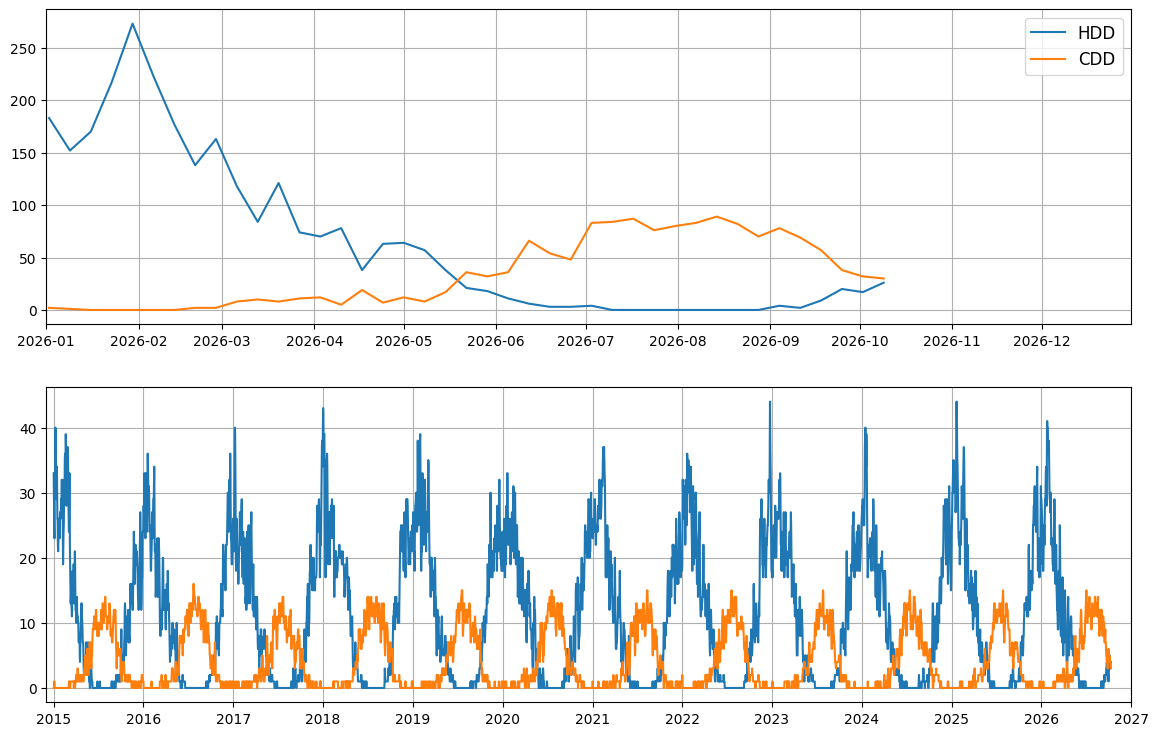

In [11]:
import matplotlib.dates as mdates
url_base = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data"
years = range(2015, pd.Timestamp.today().year + 1)
frames = {"Heating": [], "Cooling": []}


for y in years:
    for kind in ["Heating", "Cooling"]:
        url = f"{url_base}/{y}/Population.{kind}.txt"
        df = pd.read_csv(url, sep="|", skiprows=3)   # check this number
        df = df.set_index("Region").T
        df.index = pd.to_datetime(df.index, format="%Y%m%d", errors="coerce")
        df = df[df.index.notna()]                     # drop any junk rows
        frames[kind].append(df)

hdd = pd.concat(frames["Heating"]).sort_index()
cdd = pd.concat(frames["Cooling"]).sort_index()


hdd_CONUS = hdd["CONUS"].astype(float)
cdd_CONUS = cdd["CONUS"].astype(float)
#print(hdd_CONUS.head())
weekly = pd.DataFrame({"hdd": hdd_CONUS.resample("W-FRI").sum(),
                       "cdd": cdd_CONUS.resample("W-FRI").sum(),
                       "days": hdd_CONUS.resample("W-FRI").count()})
weekly = weekly[weekly["days"] == 7].drop(columns="days")

#print(weekly.head(20))
#print(weekly.tail(20))
fig, (ax2, ax1) = plt.subplots(2, 1,  figsize = (14,9))

temp_current_year = weekly.loc[str(current_year)]
ax2.plot(temp_current_year.index, temp_current_year["hdd"], label = "HDD")
ax2.plot(temp_current_year.index, temp_current_year["cdd"], label = "CDD")

ax1.plot(hdd_CONUS, label = "HDD")
ax1.plot(cdd_CONUS, label = "CDD")
print(cdd_CONUS.head())
for ax in (ax2, ax1):
    ax.grid()
    
ax2.set_xlim(pd.Timestamp(f"{current_year}-01-01"), pd.Timestamp(f"{current_year}-12-31"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.set_xlim(pd.Timestamp(f"2014-12-01"), pd.Timestamp(f"{current_year + 1}"))
ax2.legend(fontsize = 12)
plt.show()